# Phase 25C — Leakage-Safe OOF Paired Refinement-Gain Label Generation

**Method:** `RA-MedFiLM-BARR` — Resource-Aware MedFiLM with Benefit-Aware Refinement Routing
**Feature specification revision:** `ra_medfilm_barr_narrowed_v1_2`
**Population:** `ROUTER_DEVELOPMENT` only — **n = 4957**
**Output:** a frozen canonical **OOF paired-gain label table**
**Classification:** `PHASE25C_EXECUTED_EVIDENCE`

### Scientific scope

For every action-available `ROUTER_DEVELOPMENT` sample *i*:

```
DeltaDice_i = Dice(candidate_refined_i, y_i) - Dice(global_i, y_i)
```

using **OUT-OF-FOLD** regional-refiner predictions only: sample *i* is scored by the fold-specific
canonical ROI-0.30 refiner whose **outer target fold** contains *i* — a fold that was completely
excluded from that refiner's gradient fitting, early-stop fitting and checkpoint selection.

`DeltaDice` is the **paired refinement gain**. It is **NOT** a causal / counterfactual effect, and it
is **NOT** a deployable router input feature.

### What Phase 25C does NOT do

| FORBIDDEN in Phase 25C | status |
|---|---|
| benefit-router training | NOT performed — Phase 25D |
| 16-D task-embedding training | NOT performed — Phase 25D |
| use of the Phase25A **final** refiner for OOF labels | NOT performed |
| `ROUTER_HOLDOUT` use | ZERO |
| VAL808 use | ZERO |
| TEST access | ZERO reads |
| Global MedFiLM re-run | ZERO forwards (p_global from the frozen cache) |
| Phase 25D start | NOT started |

## §2 — Bootstrap, imports and artifact paths

In [1]:
import hashlib, json, sys
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path(r"D:/Softfors/jup")
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "notebooks/phasewise/phase_25c_paired_gain_labels/code"))
import phase25c_common as C
AUD = ROOT / "reports" / "audits"
TAB = ROOT / "reports" / "tables"
FIGD = ROOT / "reports" / "figures" / "phase25c_paired_gain_labels"

def _j(p):
    p = Path(p)
    return json.loads(p.read_text(encoding="utf-8")) if p.exists() else {}

def sha(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()

def sty(df, key, fmts=None):
    fmts = fmts or {}
    return (df.style.format(fmts).set_uuid("p25c-" + key)
            .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}]))

assertions = []
def chk(name, ok, detail=None):
    assertions.append((name, bool(ok), detail))
    print(("[PASS] " if ok else "[FAIL] ") + name + ("" if detail is None else f" :: {detail}"))

def fig(name, caption):
    # Embed a frozen on-disk PNG verbatim. The bytes on disk are the artifact of
    # record, so they are passed explicitly -- Image(filename=...) re-reads (and, for
    # an in-flight mpl writer, can observe a torn/truncated tail), whereas
    # Image(data=...) fixes the payload at call time.
    from IPython.display import Image, display, Markdown
    p = FIGD / name
    display(Markdown(f"**{caption}**"))
    if not p.exists():
        print("MISSING FIGURE:", name)
        return
    raw = p.read_bytes()
    assert raw[:8] == bytes([137, 80, 78, 71, 13, 10, 26, 10]), f"unusable figure: {name}"
    assert raw.rfind(b"IEND") >= len(raw) - 12, f"unusable figure (no IEND): {name}"
    display(Image(data=raw))

LAB = pd.read_csv(C.LABEL_CSV)
print("Phase 25C notebook bootstrap ok; label rows:", len(LAB))

Phase 25C notebook bootstrap ok; label rows: 4957


## §3 — Authorized predecessor binding

In [2]:
repair = _j(AUD / "phase25b_stage_semantics_repair_final_check.json")
print("predecessor terminal:", repair.get("terminal"))
chk("predecessor terminal exact",
    repair.get("terminal") == C.EXPECTED["predecessor_terminal"],
    repair.get("terminal"))
chk("predecessor repair all_pass", repair.get("all_pass") is True)

predecessor terminal: PHASE25B_HANDOFF_SEMANTICS_REPAIRED__PHASE25C_OOF_PAIRED_GAIN_LABEL_GENERATION_ELIGIBLE_NOT_STARTED
[PASS] predecessor terminal exact :: PHASE25B_HANDOFF_SEMANTICS_REPAIRED__PHASE25C_OOF_PAIRED_GAIN_LABEL_GENERATION_ELIGIBLE_NOT_STARTED
[PASS] predecessor repair all_pass


## §4 — Phase24 v1.2 binding

In [3]:
b24 = _j(AUD / "phase25c_phase24_binding.json")
print(json.dumps({k: b24[k] for k in ("phase24_v1_2_status",
      "phase24_notebook_sha_matches", "roi_proposal_threshold",
      "segmentation_output_threshold")}, indent=1))
chk("phase24 v1.2 COMPLETE_FROZEN", b24.get("phase24_v1_2_status") == "COMPLETE_FROZEN")
chk("phase24 notebook SHA exact", b24.get("phase24_notebook_sha_matches") is True)

{
 "phase24_v1_2_status": "COMPLETE_FROZEN",
 "phase24_notebook_sha_matches": true,
 "roi_proposal_threshold": 0.3,
 "segmentation_output_threshold": 0.5
}
[PASS] phase24 v1.2 COMPLETE_FROZEN
[PASS] phase24 notebook SHA exact


## §5 — Phase25A binding

In [4]:
b25a = _j(AUD / "phase25c_phase25a_binding.json")
print(json.dumps({k: b25a[k] for k in ("phase25a_notebook_sha_matches",
      "crossfit_protocol_verdict", "outer_folds",
      "final_refiner_used_for_oof")}, indent=1))
chk("phase25a notebook SHA exact", b25a.get("phase25a_notebook_sha_matches") is True)
chk("phase25a final refiner NOT used for OOF",
    b25a.get("final_refiner_used_for_oof") is False)

{
 "phase25a_notebook_sha_matches": true,
 "crossfit_protocol_verdict": "PHASE25A_CROSSFIT_PROTOCOL_FROZEN",
 "outer_folds": 3,
 "final_refiner_used_for_oof": false
}
[PASS] phase25a notebook SHA exact
[PASS] phase25a final refiner NOT used for OOF


## §6 — Phase25B binding

In [5]:
b25b = _j(AUD / "phase25c_phase25b_binding.json")
print(json.dumps({k: b25b[k] for k in ("phase25b_notebook_sha_matches",
      "matrix_sha_matches", "metadata_sha_matches", "schema_sha_matches",
      "phase25b_feature_values_used_for_label_generation")}, indent=1))
chk("phase25b notebook SHA exact", b25b.get("phase25b_notebook_sha_matches") is True)
chk("phase25b matrix SHA exact", b25b.get("matrix_sha_matches") is True)
chk("phase25b metadata SHA exact", b25b.get("metadata_sha_matches") is True)
chk("phase25b schema SHA exact", b25b.get("schema_sha_matches") is True)
chk("feature values NOT used for label generation",
    b25b.get("phase25b_feature_values_used_for_label_generation") is False)

{
 "phase25b_notebook_sha_matches": true,
 "matrix_sha_matches": true,
 "metadata_sha_matches": true,
 "schema_sha_matches": true,
 "phase25b_feature_values_used_for_label_generation": false
}
[PASS] phase25b notebook SHA exact
[PASS] phase25b matrix SHA exact
[PASS] phase25b metadata SHA exact
[PASS] phase25b schema SHA exact
[PASS] feature values NOT used for label generation


## §7 — Stage ownership

| stage | role | owner |
|---|---|---|
| 25B | 202-D GT-free pre-refinement features | frozen |
| **25C** | **OOF paired refinement-gain labels** | **this phase** |
| 25D | benefit-router training + 16-D task embedding | NOT started |

The 16-D task embedding is trained **only** in Phase 25D. Phase 25C never instantiates the router.

In [6]:
ent = _j(AUD / "phase25c_entry_gate.json")
print("entry gate:", ent.get("n_passed"), "/", ent.get("n_checks"), ent.get("verdict"))
chk("entry gate PASS", ent.get("verdict") == "PHASE25C_ENTRY_GATE_PASS")
chk("entry gate all_pass", ent.get("all_pass") is True)

entry gate: 30 / 30 PHASE25C_ENTRY_GATE_PASS
[PASS] entry gate PASS
[PASS] entry gate all_pass


## §8 — Population

In [7]:
pop = pd.read_csv(TAB / "phase25c_population_accounting.csv")
display(sty(pop, "pop"))
_pop_n = dict(zip(pop["population"], pop["n"]))
chk("population rows = 4957", int(_pop_n["labeled_rows"]) == 4957)
chk("action_available = 4957", int(_pop_n["action_available"]) == 4957)
chk("action_unavailable = 0", int(_pop_n["action_unavailable"]) == 0)

,population,n,used_for_phase25c
0,ROUTER_DEVELOPMENT,4957,nan
1,action_available,4957,nan
2,action_unavailable,0,nan
3,labeled_rows,4957,nan
4,ROUTER_HOLDOUT,875,False


[PASS] population rows = 4957
[PASS] action_available = 4957
[PASS] action_unavailable = 0


## §9 — TEST / holdout / VAL locks

In [8]:
tlock = _j(AUD / "phase25c_test_lock_audit.json")
print(json.dumps(tlock, indent=1)[:900])
chk("TEST reads = 0", tlock.get("test_reads") == 0)
chk("ROUTER_HOLDOUT reads = 0", tlock.get("holdout_reads") == 0)
chk("VAL reads = 0", tlock.get("val_reads") == 0)

{
 "artifact": "phase25c_test_lock_audit",
 "phase": "25C",
 "method": "RA-MedFiLM-BARR",
 "router_holdout": {
  "image_reads": 0,
  "gt_reads": 0,
  "feature_reads_for_phase25c": 0,
  "refiner_inference": 0,
  "global_inference": 0,
  "dice": 0,
  "deltadice": 0,
  "ids_in_label_table": 0
 },
 "val808": {
  "image_reads": 0,
  "gt_reads": 0,
  "refiner_inference": 0,
  "dice": 0,
  "deltadice": 0
 },
 "test": {
  "image_reads": 0,
  "mask_reads": 0,
  "inference": 0,
  "visualization": 0,
  "metrics": 0
 },
 "holdout_reads": 0,
 "val_reads": 0,
 "test_reads": 0,
 "verdict": "PHASE25C_LOCK_AUDIT_PASS",
 "generated_utc": "2026-09-30T17:18:00+00:00"
}
[PASS] TEST reads = 0
[PASS] ROUTER_HOLDOUT reads = 0
[PASS] VAL reads = 0


## §10 — Outer-fold assignments

In [9]:
assign = C.load_outer_fold_assignment()
from collections import Counter
cnt = Counter(assign.values())
print("outer-fold counts:", dict(sorted(cnt.items())))
chk("every DEV sample in exactly one outer fold", len(assign) == 4957)
chk("fold0 outer n = 1657", cnt[0] == 1657)
chk("fold1 outer n = 1652", cnt[1] == 1652)
chk("fold2 outer n = 1648", cnt[2] == 1648)

outer-fold counts: {0: 1657, 1: 1652, 2: 1648}
[PASS] every DEV sample in exactly one outer fold
[PASS] fold0 outer n = 1657
[PASS] fold1 outer n = 1652
[PASS] fold2 outer n = 1648


## §11 — Fold checkpoint inventory

In [10]:
fb = pd.read_csv(TAB / "phase25c_fold_checkpoint_binding.csv")
display(sty(fb, "fb"))
fbj = _j(AUD / "phase25c_fold_checkpoint_binding.json")
chk("all fold checkpoints bound", fbj.get("all_fold_checkpoints_bound") is True)
chk("phase25a final NOT authorized for OOF",
    fbj.get("phase25a_final_refiner_not_authorized_confirmed") is True)

,outer_fold,checkpoint,checkpoint_sha256,n_oof_samples
0,0,fold0/best.pt,40b7573a4a15483f895fece8b9624f4f23b1ee040e294b7594ed3cdf8438fc1c,1657
1,1,fold1/best.pt,512cc116b2a1baa5368711f438dfd0b2aabff1448d02fbc0c369b91da8ffc1ce,1652
2,2,fold2/best.pt,1259e2d938a7e6e81ad9ddce4bfc25189e20858e8f201d167663c26c72c269ec,1648


[PASS] all fold checkpoints bound
[PASS] phase25a final NOT authorized for OOF


## §12 — Cross-fit leakage proof

In [11]:
lf = _j(AUD / "phase25c_crossfit_leakage_audit.json")
print("verdict:", lf.get("verdict"))
print("violations:", lf.get("crossfit_leakage_violations"))
cov = pd.read_csv(TAB / "phase25c_crossfit_coverage.csv")
display(sty(cov, "cov"))
chk("cross-fit leakage = 0", lf.get("crossfit_leakage_violations") == 0)
chk("all in exactly one outer target",
    lf.get("samples_in_exactly_one_outer_target") == 4957)
chk("self-fit leak = 0", lf.get("samples_in_own_fit_population") == 0)
chk("self-early-stop leak = 0", lf.get("samples_in_own_early_stop_population") == 0)

verdict: PHASE25C_CROSSFIT_LEAKAGE_CLEAN
violations: 0


,fold,outer_target_n,labeled_n,fit_n,early_stop_n,outer_intersect_fit,outer_intersect_early_stop
0,0,1657,1657,2964,336,0,0
1,1,1652,1652,2975,330,0,0
2,2,1648,1648,2977,332,0,0


[PASS] cross-fit leakage = 0
[PASS] all in exactly one outer target
[PASS] self-fit leak = 0
[PASS] self-early-stop leak = 0


## §13 — Canonical global-cache binding

In [12]:
gc = _j(AUD / "phase25c_global_cache_binding.json")
print(json.dumps({k: gc[k] for k in ("global_model_forward_passes",
      "global_checkpoint_sha_matches", "prob512_dtype", "roi_proposal_threshold",
      "segmentation_output_threshold")}, indent=1))
chk("global forward passes = 0", gc.get("global_model_forward_passes") == 0)
chk("global checkpoint SHA matches", gc.get("global_checkpoint_sha_matches") is True)
chk("prob512 is float32", gc.get("prob512_dtype") == "float32")

{
 "global_model_forward_passes": 0,
 "global_checkpoint_sha_matches": true,
 "prob512_dtype": "float32",
 "roi_proposal_threshold": 0.3,
 "segmentation_output_threshold": 0.5
}
[PASS] global forward passes = 0
[PASS] global checkpoint SHA matches
[PASS] prob512 is float32


## §14 — ROI-0.30 binding

In [13]:
print("constants:", C.ROI_PROPOSAL_THRESHOLD, C.SEGMENTATION_OUTPUT_THRESHOLD)
chk("ROI proposal threshold = 0.30", abs(C.ROI_PROPOSAL_THRESHOLD - 0.30) < 1e-12)
chk("segmentation output threshold = 0.50",
    abs(C.SEGMENTATION_OUTPUT_THRESHOLD - 0.50) < 1e-12)

constants: 0.3 0.5
[PASS] ROI proposal threshold = 0.30
[PASS] segmentation output threshold = 0.50


## §15 — Refiner inference execution binding

In [14]:
ib = _j(AUD / "phase25c_refiner_inference_execution_binding.json")
print(json.dumps(ib.get("binding", {}), indent=1))
chk("binding classification PRE_EXECUTION_OPERATIONAL_BINDING",
    ib.get("classification") == "PRE_EXECUTION_OPERATIONAL_BINDING")
chk("binding selected before OOF outcomes",
    ib.get("selected_before_oof_outcomes") is True)
chk("FP32 inference", ib.get("binding", {}).get("inference_precision") == "float32")
chk("no TTA", ib.get("binding", {}).get("tta") is False)
chk("no checkpoint ensemble", ib.get("binding", {}).get("checkpoint_ensemble") is False)

{
 "inference_precision": "float32",
 "autocast_enabled": false,
 "amp_enabled": false,
 "amp_rationale": "AMP kernel selection depends on batch MEMBERSHIP; FP32 removes that non-determinism so OOF inference is a pure function of the sample.",
 "model_mode": "eval",
 "inference_context": "torch.inference_mode()",
 "grad_enabled": false,
 "tta": false,
 "stochastic_augmentation": false,
 "dropout_behavior": "inactive (model.eval(); architecture has no dropout)",
 "checkpoint_ensemble": false,
 "checkpoint_averaging": false,
 "best_of_multiple_predictions": false,
 "sample_order": "deterministic: sort by dataset/domain then sample_id",
 "batch_size": 8,
 "drop_last": false,
 "refiner_input_channels": 4,
 "refiner_input_resolution": 256,
 "refiner_input_construction": "[R,G,B] = rgb_crop(uint8)/255.0 float32 ; [p_global_crop] = prob_crop float16 -> float32  (exact BARRRefinerCropDataset train=False path)",
 "logit_to_probability": "sigmoid(logits.float())",
 "one_primary_forward_per_sampl

## §16 — Crop / refiner input reconstruction

In [15]:
ra = _j(AUD / "phase25c_fullfield_reconstruction_audit.json")
print(json.dumps(ra.get("geometry_identity_checks", {}), indent=1))
print("synthetic:", [(c["case"], c["outside_unchanged"], c["inside_replaced_exactly"])
                     for c in ra.get("synthetic_cases", [])])
chk("reconstruction verified", ra.get("verdict") == "PHASE25C_RECONSTRUCTION_VERIFIED")
chk("all outside unchanged", ra.get("all_outside_unchanged") is True)
chk("all inside replaced", ra.get("all_inside_replaced") is True)

{
 "y1_plus_pad_equals_clip_y1": true,
 "x1_plus_pad_equals_clip_x1": true
}
synthetic: [('rect', True, True), ('off_canvas', True, True), ('small_blob', True, True)]
[PASS] reconstruction verified
[PASS] all outside unchanged
[PASS] all inside replaced


## §17 — Full-field inverse transform

In [16]:
print("inverse:", ra.get("inverse_transform"))
chk("geometry y-identity", ra["geometry_identity_checks"]["y1_plus_pad_equals_clip_y1"])
chk("geometry x-identity", ra["geometry_identity_checks"]["x1_plus_pad_equals_clip_x1"])

inverse: affine resize of the 256x256 refined crop to crop_side_pixels^2 (bilinear, PIL mode F), remove external zero padding, place at (clip_y1, clip_x1) on the 512 canvas
[PASS] geometry y-identity
[PASS] geometry x-identity


## §18 — Fusion rule

In [17]:
print(ra.get("fusion_rule"))
chk("fusion is deterministic copy+replace (documented)",
    "replace" in ra.get("fusion_rule", ""))

p_candidate_full = copy(p_global); inside the valid canonical ROI replace with the inverse-transformed refined probability; outside leave p_global unchanged. No alpha blending, no learned fusion, no morphology, no post-safety, no GT-based correction.
[PASS] fusion is deterministic copy+replace (documented)


## §19 — Segmentation threshold

In [18]:
ts = _j(AUD / "phase25c_threshold_semantics_audit.json")
print(json.dumps(ts, indent=1)[:800])
chk("Dice uses segmentation threshold 0.50", ts.get("dice_uses_segmentation_threshold") is True)
chk("Dice does NOT use ROI threshold", ts.get("dice_uses_roi_threshold") is False)

{
 "artifact": "phase25c_threshold_semantics_audit",
 "phase": "25C",
 "method": "RA-MedFiLM-BARR",
 "roi_proposal_threshold": 0.3,
 "roi_proposal_threshold_role": "ROI_PROPOSAL (bbox/geometry/ACTION_AVAILABLE only)",
 "segmentation_output_threshold": 0.5,
 "segmentation_output_threshold_role": "SEGMENTATION_OUTPUT (the Dice mask threshold)",
 "dice_uses_segmentation_threshold": true,
 "dice_uses_roi_threshold": false,
 "roi_threshold_is_not_dice_threshold": true,
 "global_mask_rule": "M_global = prob512 >= 0.50",
 "candidate_mask_rule": "M_candidate = p_candidate_full >= 0.50",
 "verdict": "PHASE25C_THRESHOLD_SEMANTICS_OK",
 "test_reads": 0,
 "generated_utc": "2026-09-30T17:07:00+00:00"
}
[PASS] Dice uses segmentation threshold 0.50
[PASS] Dice does NOT use ROI threshold


## §20 — Dice metric binding

In [19]:
mb = _j(AUD / "phase25c_metric_binding.json")
print(json.dumps({k: mb[k] for k in ("metric_source_file", "metric_function",
      "metric_source_sha256", "formula", "epsilon",
      "new_dice_formula_introduced")}, indent=1))
chk("canonical Dice bound", mb.get("verdict") == "PHASE25C_METRIC_BOUND")
chk("no new Dice formula", mb.get("new_dice_formula_introduced") is False)
chk("no conflicting metric definitions", mb.get("conflicting_metric_definitions_found") is False)

{
 "metric_source_file": "src/metrics/evaluation_metrics.py",
 "metric_function": "dice",
 "metric_source_sha256": "6c515f6f1a495315c79238292c385a082ae8347489130ad5bff34d74c4f181f6",
 "formula": "dice = (2*tp + eps) / (2*tp + fp + fn + eps)",
 "epsilon": 1e-07,
 "new_dice_formula_introduced": false
}
[PASS] canonical Dice bound
[PASS] no new Dice formula
[PASS] no conflicting metric definitions


## §21–§23 — Fold OOF execution (fold0 / fold1 / fold2) and full coverage

In [20]:
for k in (0, 1, 2):
    n = int((LAB["outer_fold"] == k).sum())
    print(f"fold{k}: OOF samples = {n}")
chk("fold0 coverage", int((LAB["outer_fold"] == 0).sum()) == 1657)
chk("fold1 coverage", int((LAB["outer_fold"] == 1).sum()) == 1652)
chk("fold2 coverage", int((LAB["outer_fold"] == 2).sum()) == 1648)
chk("full coverage = 4957", len(LAB) == 4957)
chk("no duplicate sample_id", LAB["sample_id"].duplicated().sum() == 0)

fold0: OOF samples = 1657
fold1: OOF samples = 1652
fold2: OOF samples = 1648
[PASS] fold0 coverage
[PASS] fold1 coverage
[PASS] fold2 coverage
[PASS] full coverage = 4957
[PASS] no duplicate sample_id


## §24 — Paired-label equation

In [21]:
resid = np.abs(LAB["delta_dice"] - (LAB["candidate_refined_dice"] - LAB["global_dice"]))
print("max identity residual:", float(resid.max()))
chk("DeltaDice identity holds (< 1e-12)", float(resid.max()) <= 1e-12)

max identity residual: 3.214117340333278e-16
[PASS] DeltaDice identity holds (< 1e-12)


## §25 — Label-table integrity

In [22]:
li = _j(AUD / "phase25c_label_integrity.json")
print(json.dumps({k: li[k] for k in ("rows", "duplicates", "nan", "inf",
      "router_holdout_ids_in_labels", "category_counts")}, indent=1))
chk("label integrity PASS", li.get("verdict") == "PHASE25C_LABEL_INTEGRITY_PASS")
chk("rows = 4957", li.get("rows") == 4957)
chk("no NaN", all(v == 0 for v in li.get("nan", {}).values()))
chk("no Inf", all(v == 0 for v in li.get("inf", {}).values()))
chk("no holdout ids", li.get("router_holdout_ids_in_labels") == 0)

{
 "rows": 4957,
 "duplicates": 0,
 "nan": {
  "global_dice": 0,
  "candidate_refined_dice": 0,
  "delta_dice": 0
 },
 "inf": {
  "global_dice": 0,
  "candidate_refined_dice": 0,
  "delta_dice": 0
 },
 "router_holdout_ids_in_labels": 0,
 "category_counts": {
  "NEUTRAL": 4340,
  "HARMFUL": 335,
  "BENEFICIAL": 282
 }
}
[PASS] label integrity PASS
[PASS] rows = 4957
[PASS] no NaN
[PASS] no Inf
[PASS] no holdout ids


## §26 — Beneficial / harmful / neutral definitions

In [23]:
catc = pd.read_csv(TAB / "phase25c_gain_category_counts.csv")
display(sty(catc, "catc"))
print(f"BENEFICIAL >= +{C.BENEFICIAL_DELTA}; HARMFUL <= {C.HARMFUL_DELTA}; NEUTRAL otherwise")
tot = int(catc[["BENEFICIAL","NEUTRAL","HARMFUL"]].sum().sum())
chk("categories exhaustive (= 4957)", tot == 4957)
chk("each sample in exactly one category",
    len(LAB) == int((LAB.groupby("gain_category").size()).sum()))

,domain,BENEFICIAL,NEUTRAL,HARMFUL,total
0,BUSI,0,511,1,512
1,ISIC,35,2048,90,2173
2,KUB,245,1191,244,1680
3,KVASIR,2,590,0,592


BENEFICIAL >= +0.02; HARMFUL <= -0.01; NEUTRAL otherwise
[PASS] categories exhaustive (= 4957)
[PASS] each sample in exactly one category


## §27 — Overall gain summary

In [24]:
ov = pd.read_csv(TAB / "phase25c_gain_summary_overall.csv")
display(sty(ov, "ov", {"mean": "{:.6f}", "median": "{:.6f}", "std": "{:.6f}"}))
print("Scientific gain magnitude is NOT a PASS criterion.")

,group,n,mean,median,std,iqr,p05,p95,min,max
0,overall,4957,0.001658,0.000453,0.014464,0.006012,-0.012441,0.021756,-0.332882,0.117450


Scientific gain magnitude is NOT a PASS criterion.


**DeltaDice distribution**

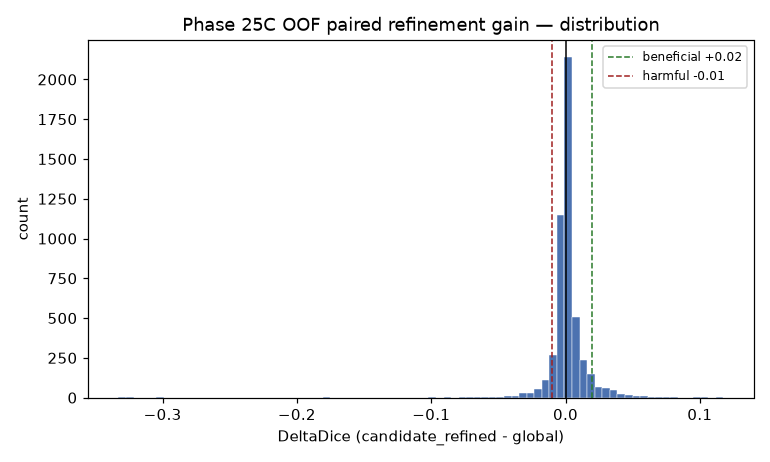

In [25]:
fig('p25c_delta_dice_distribution.png', 'DeltaDice distribution')

## §28 — Gain by domain

In [26]:
bd = pd.read_csv(TAB / "phase25c_gain_summary_by_domain.csv")
display(sty(bd, "bd", {"mean": "{:.6f}", "median": "{:.6f}", "std": "{:.6f}"}))

,group,n,mean,median,std,iqr,p05,p95,min,max
0,domain:BUSI,512,0.000143,0.000098,0.001917,0.002055,-0.002703,0.002913,-0.015280,0.007994
1,domain:ISIC,2173,0.000900,0.000452,0.007588,0.005788,-0.009109,0.011802,-0.049685,0.069444
2,domain:KUB,1680,0.003668,0.002502,0.023106,0.016901,-0.024350,0.034884,-0.332882,0.117450
3,domain:KVASIR,592,0.000047,0.000011,0.002151,0.001667,-0.002431,0.002176,-0.007267,0.027093


**DeltaDice by domain**

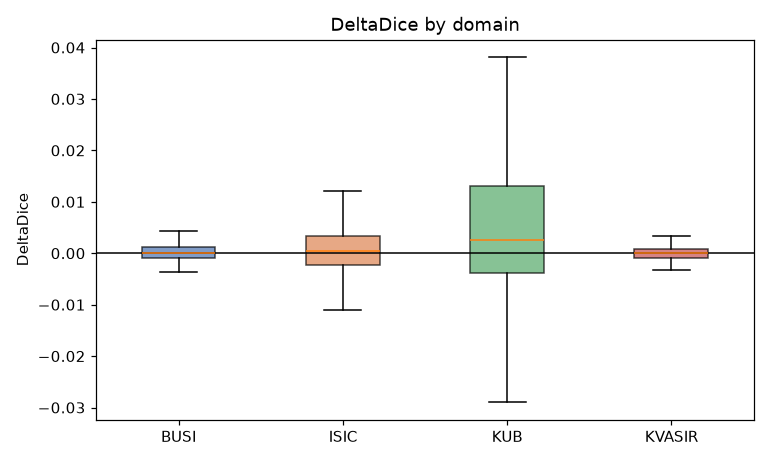

In [27]:
fig('p25c_delta_dice_by_domain.png', 'DeltaDice by domain')

**Gain category by domain**

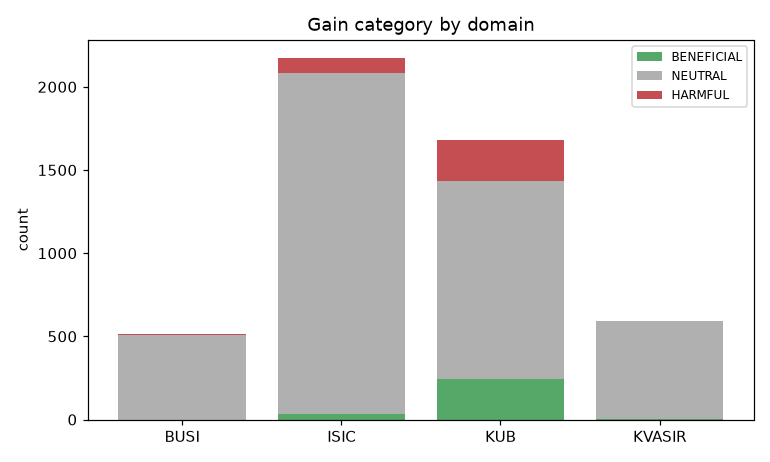

In [28]:
fig('p25c_gain_category_by_domain.png', 'Gain category by domain')

## §29 — Gain by fold

In [29]:
bf = pd.read_csv(TAB / "phase25c_gain_summary_by_fold.csv")
display(sty(bf, "bf", {"mean": "{:.6f}", "median": "{:.6f}", "std": "{:.6f}"}))

,group,n,mean,median,std,iqr,p05,p95,min,max
0,fold:0,1657,0.001343,0.000536,0.016973,0.005353,-0.010064,0.017740,-0.332882,0.097746
1,fold:1,1652,0.001584,0.000360,0.013900,0.006578,-0.015111,0.025042,-0.177094,0.117450
2,fold:2,1648,0.002049,0.000512,0.012080,0.006164,-0.012017,0.024380,-0.069602,0.076335


**DeltaDice by outer fold**

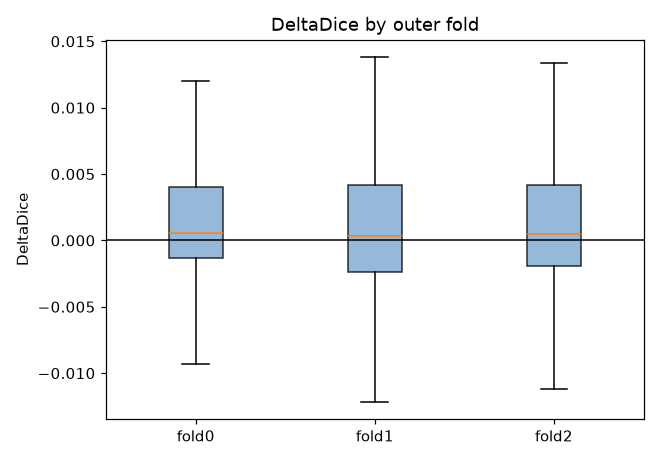

In [30]:
fig('p25c_delta_dice_by_outer_fold.png', 'DeltaDice by outer fold')

## §30 — Global vs candidate plot

**Global vs candidate-refined Dice**

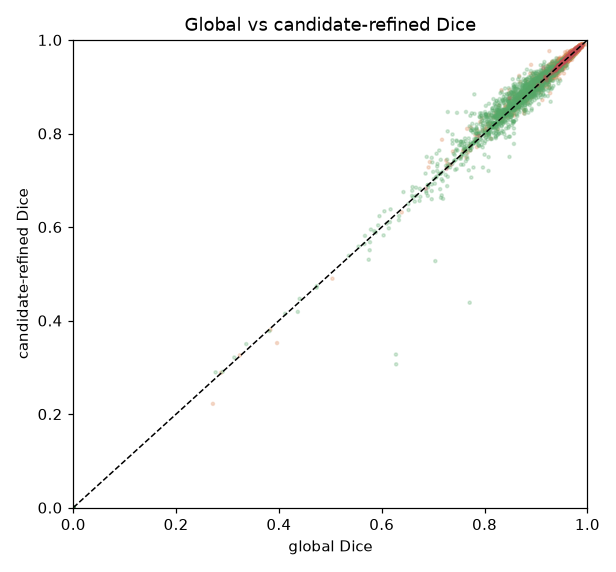

In [31]:
fig('p25c_global_vs_candidate_dice.png', 'Global vs candidate-refined Dice')

## §31 — Delta distribution vs global Dice

**DeltaDice vs global Dice**

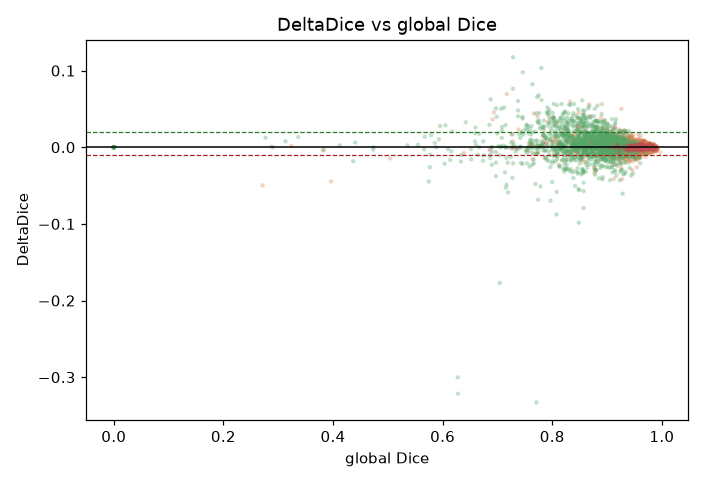

In [32]:
fig('p25c_delta_vs_global_dice.png', 'DeltaDice vs global Dice')

## §32 — Fixed qualitative gallery

In [33]:
print("Gallery selection is FIXED by a stable sample-id rule, independent of DeltaDice.")

Gallery selection is FIXED by a stable sample-id rule, independent of DeltaDice.


**Fixed OOF examples (RGB crop | p_global crop | GT crop)**

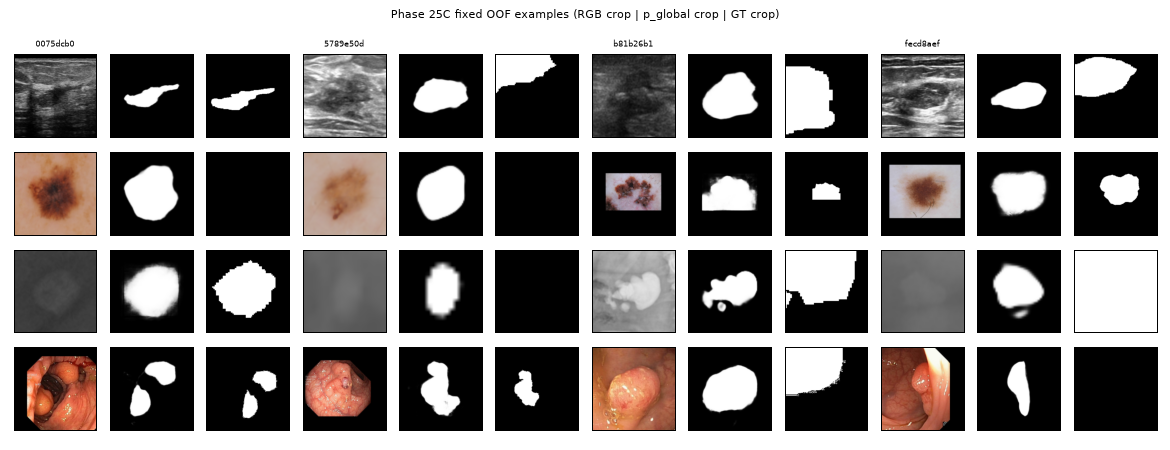

In [34]:
fig('p25c_fixed_oof_examples.png', 'Fixed OOF examples (RGB crop | p_global crop | GT crop)')

## §33 — Determinism audit

In [35]:
det = _j(AUD / "phase25c_oof_determinism.json")
print(json.dumps({k: det[k] for k in ("subset_size", "replay_method",
      "max_candidate_dice_diff", "max_delta_dice_diff",
      "candidate_mask_mismatches", "verdict")}, indent=1))
chk("OOF determinism PASS", det.get("verdict") == "PHASE25C_OOF_DETERMINISM_PASS")
chk("subset size = 64", det.get("subset_size") == 64)
chk("0 mask mismatches", det.get("candidate_mask_mismatches") == 0)

{
 "subset_size": 64,
 "replay_method": "replayed inside the ORIGINAL canonical fold-filtered batch of 8",
 "max_candidate_dice_diff": 1.1102230246251565e-16,
 "max_delta_dice_diff": 9.93129189996722e-17,
 "candidate_mask_mismatches": 0,
 "verdict": "PHASE25C_OOF_DETERMINISM_PASS"
}
[PASS] OOF determinism PASS
[PASS] subset size = 64
[PASS] 0 mask mismatches


**Cross-fit coverage**

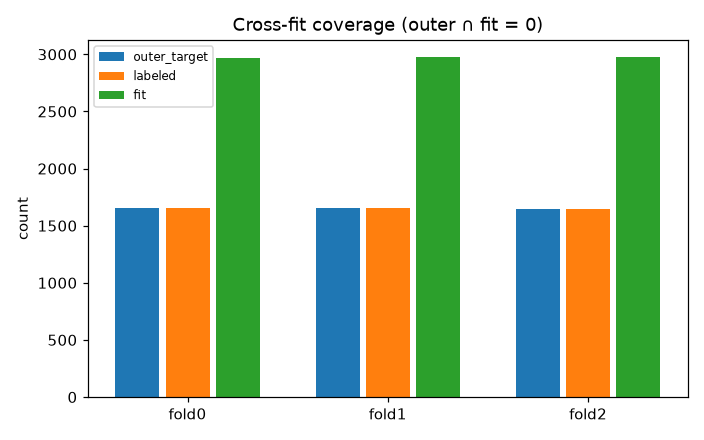

In [36]:
fig('p25c_crossfit_coverage.png', 'Cross-fit coverage')

## §34 — Phase25B join integrity

In [37]:
ji = _j(AUD / "phase25c_phase25b_join_integrity.json")
print(json.dumps(ji, indent=1)[:900])
chk("join integrity PASS", ji.get("verdict") == "PHASE25C_JOIN_INTEGRITY_PASS")
chk("sample_id sets identical", ji.get("sample_id_sets_identical") is True)
chk("feature_row_index exact", ji.get("feature_row_index_mapping_exact") is True)

{
 "artifact": "phase25c_phase25b_join_integrity",
 "phase": "25C",
 "method": "RA-MedFiLM-BARR",
 "join_key": "sample_id",
 "phase25c_n": 4957,
 "phase25b_n": 4957,
 "development_n": 4957,
 "sample_id_sets_identical": true,
 "feature_row_index_mapping_exact": true,
 "task_id_exact": true,
 "domain_exact": true,
 "outer_fold_exact": true,
 "outer_fold_representation_note": "Phase25B metadata stores outer_fold as 'fold0'/'fold1'/'fold2'; Phase25C stores it as int 0/1/2. Values agree exactly after normalisation.",
 "outer_fold_present": true,
 "phase25b_feature_cache_modified": false,
 "all_pass": true,
 "verdict": "PHASE25C_JOIN_INTEGRITY_PASS",
 "test_reads": 0,
 "generated_utc": "2026-09-30T17:10:00+00:00"
}
[PASS] join integrity PASS
[PASS] sample_id sets identical
[PASS] feature_row_index exact


## §35 — No-router assertion

In [38]:
sg = _j(AUD / "phase25c_scope_guard.json")
print(json.dumps(sg, indent=1)[:900])
chk("router NOT instantiated", sg.get("BARRBenefitRouterV1_instantiated") is False)
chk("router training runs = 0", sg.get("router_training_runs") == 0)
chk("router inference runs = 0", sg.get("router_inference_runs") == 0)

{
 "artifact": "phase25c_scope_guard",
 "phase": "25C",
 "method": "RA-MedFiLM-BARR",
 "BARRBenefitRouterV1_instantiated": false,
 "router_training_runs": 0,
 "router_inference_runs": 0,
 "task_embedding_instantiated": false,
 "task_embedding_training_runs": 0,
 "Huber_loss_training": 0,
 "global_model_forwards": 0,
 "refiner_forward_samples_processed": 4957,
 "fold0_samples": 1657,
 "fold1_samples": 1652,
 "fold2_samples": 1648,
 "final_refiner_oof_forwards": 0,
 "tta_used": false,
 "checkpoint_ensemble_used": false,
 "holdout_reads": 0,
 "holdout_feature_reads": 0,
 "val_reads": 0,
 "val_dice_computed": 0,
 "test_reads": 0,
 "test_inference": 0,
 "verdict": "PHASE25C_SCOPE_GUARD_PASS",
 "generated_utc": "2026-09-30T17:18:00+00:00"
}
[PASS] router NOT instantiated
[PASS] router training runs = 0
[PASS] router inference runs = 0


## §36 — No-task-embedding assertion

In [39]:
chk("task embedding NOT instantiated", sg.get("task_embedding_instantiated") is False)
chk("task embedding training runs = 0", sg.get("task_embedding_training_runs") == 0)
chk("Huber loss training = 0", sg.get("Huber_loss_training") == 0)

[PASS] task embedding NOT instantiated
[PASS] task embedding training runs = 0
[PASS] Huber loss training = 0


## §37 — No-holdout assertion

In [40]:
chk("holdout reads = 0", sg.get("holdout_reads") == 0)
chk("holdout feature reads = 0", sg.get("holdout_feature_reads") == 0)

[PASS] holdout reads = 0
[PASS] holdout feature reads = 0


## §38 — No-VAL assertion

In [41]:
chk("VAL reads = 0", sg.get("val_reads") == 0)
chk("VAL dice = 0", sg.get("val_dice_computed") == 0)

[PASS] VAL reads = 0
[PASS] VAL dice = 0


## §39 — No-TEST assertion

In [42]:
chk("TEST reads = 0", sg.get("test_reads") == 0)
chk("TEST inference = 0", sg.get("test_inference") == 0)

[PASS] TEST reads = 0
[PASS] TEST inference = 0


## §40 — Phase25D handoff

In [43]:
ho = _j(AUD / "phase25c_phase25d_handoff_schema.json")
print(json.dumps(ho, indent=1)[:1200])
chk("handoff ready", ho.get("verdict") == "PHASE25C_PHASE25D_HANDOFF_READY")
chk("25C router_instantiated = false", ho.get("phase25c", {}).get("router_instantiated") is False)
chk("25C task_embedding_trained = false",
    ho.get("phase25c", {}).get("task_embedding_trained") is False)

{
 "artifact": "phase25c_phase25d_handoff_schema",
 "phase": "25C",
 "method": "RA-MedFiLM-BARR",
 "architecture_revision": "ra_medfilm_barr_narrowed_v1_2",
 "phase25b_provides": {
  "features": "202-D GT-free pre-refinement features",
  "numeric_dimensions": 202,
  "fields": [
   "sample_id",
   "feature_row_index",
   "task_id",
   "domain",
   "outer_fold",
   "action_available"
  ]
 },
 "phase25c_provides": {
  "fields": [
   "sample_id",
   "outer_fold",
   "delta_dice (continuous target)",
   "gain_category",
   "global_dice",
   "candidate_refined_dice",
   "fold_refiner_checkpoint_sha"
  ],
  "label_csv": "data_cache/phase25c_barr_oof_paired_gain_labels_v1_2/phase25c_oof_paired_gain_labels.csv",
  "label_csv_sha256": "fd6ca32c33a3bddb75f986b1350d54ec35b11d3bf5cb0fdc029962a5aa94865f",
  "primary_target": "delta_dice",
  "secondary_target": "gain_category",
  "join_key": "sample_id"
 },
 "phase25d_will": [
  "join Phase25B 202-D features + Phase25C labels by sample_id",
  "verify

## §41 — Final assertions

In [44]:
n_pass = sum(1 for _, ok, _ in assertions if ok)
n_fail = sum(1 for _, ok, _ in assertions if not ok)
print(f"assertions: {n_pass} passed / {n_fail} failed / {len(assertions)} total")
for name, ok, detail in assertions:
    if not ok:
        print("  [FAIL]", name, detail)
chk("all assertions passed", n_fail == 0)
print("No router-training cells; no training curves; OOF labels only.")

assertions: 84 passed / 0 failed / 84 total
[PASS] all assertions passed
No router-training cells; no training curves; OOF labels only.
